# Load libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import plotly.express as px
from category_encoders import TargetEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

#  Load data

In [2]:
df = pd.read_csv(r"../data/advertising.csv")
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Gender,Country,Timestamp,Clicked on Ad
0,62.26,32.0,69481.85,172.83,Decentralized real-time circuit,Lisafort,Male,Svalbard & Jan Mayen Islands,2016-06-09 21:43:05,0
1,41.73,31.0,61840.26,207.17,Optional full-range projection,West Angelabury,Male,Singapore,2016-01-16 17:56:05,0
2,44.40,30.0,57877.15,172.83,Total 5thgeneration standardization,Reyesfurt,Female,Guadeloupe,2016-06-29 10:50:45,0
3,59.88,28.0,56180.93,207.17,Balanced empowering success,New Michael,Female,Zambia,2016-06-21 14:32:32,0
4,49.21,30.0,54324.73,201.58,Total 5thgeneration standardization,West Richard,Female,Qatar,2016-07-21 10:54:35,1


# Exploratory Data Analysis (EDA)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  10000 non-null  float64
 1   Age                       10000 non-null  float64
 2   Area Income               10000 non-null  float64
 3   Daily Internet Usage      10000 non-null  float64
 4   Ad Topic Line             10000 non-null  object 
 5   City                      10000 non-null  object 
 6   Gender                    10000 non-null  object 
 7   Country                   10000 non-null  object 
 8   Timestamp                 10000 non-null  object 
 9   Clicked on Ad             10000 non-null  int64  
dtypes: float64(4), int64(1), object(5)
memory usage: 781.4+ KB


In [4]:
#as we can see there are no missing value we can verify that
df.isnull().sum()

Daily Time Spent on Site    0
Age                         0
Area Income                 0
Daily Internet Usage        0
Ad Topic Line               0
City                        0
Gender                      0
Country                     0
Timestamp                   0
Clicked on Ad               0
dtype: int64

In [5]:
#checking duplicated data
df.duplicated().sum()

215

In [6]:
#deleting duplicated data
df.drop_duplicates(inplace=True)
df

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Gender,Country,Timestamp,Clicked on Ad
0,62.26,32.0,69481.85,172.83,Decentralized real-time circuit,Lisafort,Male,Svalbard & Jan Mayen Islands,2016-06-09 21:43:05,0
1,41.73,31.0,61840.26,207.17,Optional full-range projection,West Angelabury,Male,Singapore,2016-01-16 17:56:05,0
2,44.40,30.0,57877.15,172.83,Total 5thgeneration standardization,Reyesfurt,Female,Guadeloupe,2016-06-29 10:50:45,0
3,59.88,28.0,56180.93,207.17,Balanced empowering success,New Michael,Female,Zambia,2016-06-21 14:32:32,0
4,49.21,30.0,54324.73,201.58,Total 5thgeneration standardization,West Richard,Female,Qatar,2016-07-21 10:54:35,1
...,...,...,...,...,...,...,...,...,...,...
9994,41.73,28.0,39799.73,217.37,Realigned intangible benchmark,Dustinchester,Female,Zambia,2016-03-20 02:44:13,0
9995,41.73,31.0,61840.26,207.17,Profound executive flexibility,West Angelabury,Male,Singapore,2016-01-03 03:22:15,1
9996,41.73,28.0,51501.38,120.49,Managed zero tolerance concept,Kennedyfurt,Male,Luxembourg,2016-05-28 12:20:15,0
9997,55.60,39.0,38067.08,124.44,Intuitive exuding service-desk,North Randy,Female,Egypt,2016-01-05 11:53:17,0


In [7]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
# just so we can split the timestamp clomun for better processing
df['month'] = df['Timestamp'].dt.month    
df['hour'] = df['Timestamp'].dt.hour 
df["weekday"] = df['Timestamp'].dt.dayofweek 

In [8]:
df.drop('Timestamp',axis=1)

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Gender,Country,Clicked on Ad,month,hour,weekday
0,62.26,32.0,69481.85,172.83,Decentralized real-time circuit,Lisafort,Male,Svalbard & Jan Mayen Islands,0,6,21,3
1,41.73,31.0,61840.26,207.17,Optional full-range projection,West Angelabury,Male,Singapore,0,1,17,5
2,44.40,30.0,57877.15,172.83,Total 5thgeneration standardization,Reyesfurt,Female,Guadeloupe,0,6,10,2
3,59.88,28.0,56180.93,207.17,Balanced empowering success,New Michael,Female,Zambia,0,6,14,1
4,49.21,30.0,54324.73,201.58,Total 5thgeneration standardization,West Richard,Female,Qatar,1,7,10,3
...,...,...,...,...,...,...,...,...,...,...,...,...
9994,41.73,28.0,39799.73,217.37,Realigned intangible benchmark,Dustinchester,Female,Zambia,0,3,2,6
9995,41.73,31.0,61840.26,207.17,Profound executive flexibility,West Angelabury,Male,Singapore,1,1,3,6
9996,41.73,28.0,51501.38,120.49,Managed zero tolerance concept,Kennedyfurt,Male,Luxembourg,0,5,12,5
9997,55.60,39.0,38067.08,124.44,Intuitive exuding service-desk,North Randy,Female,Egypt,0,1,11,1


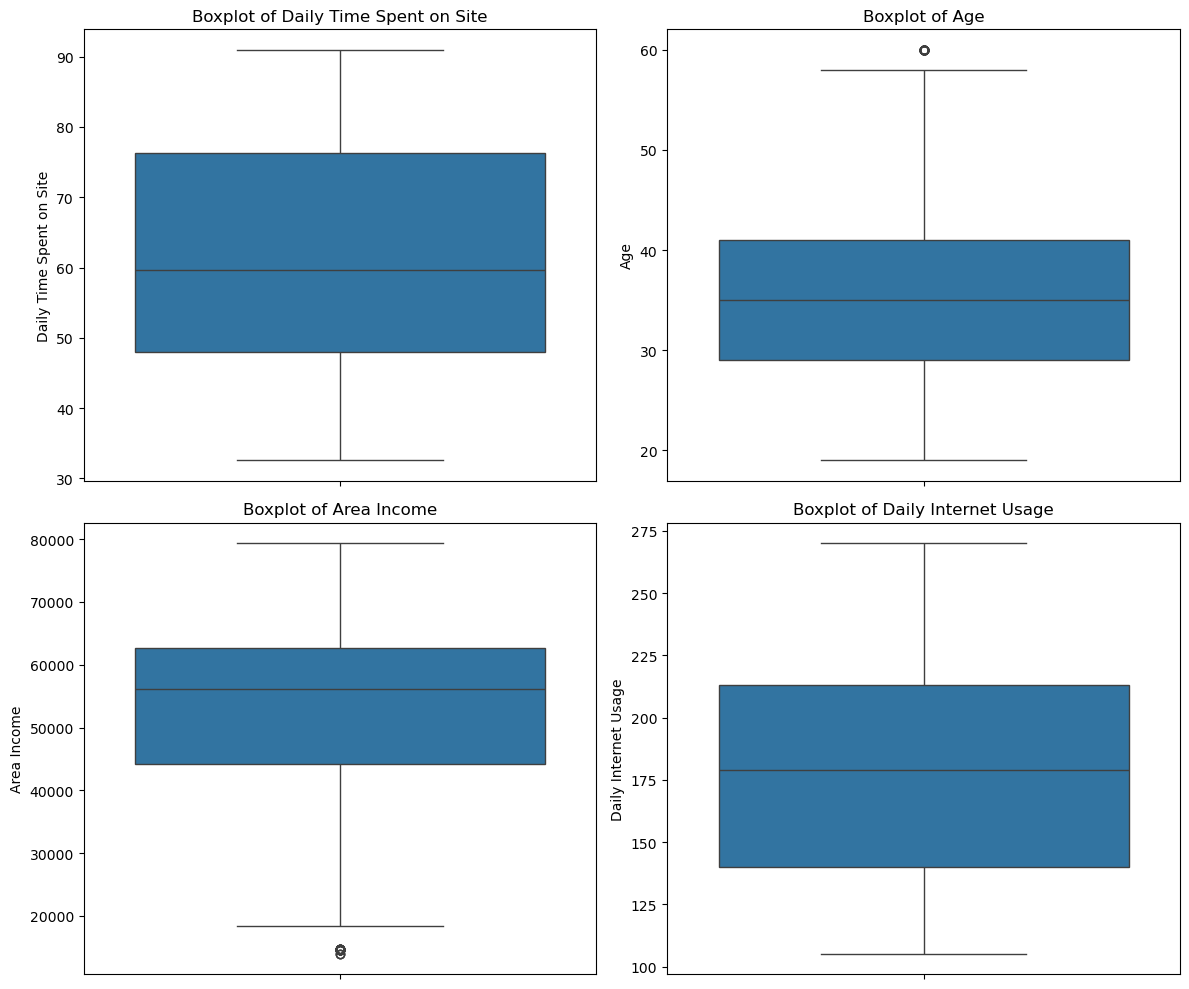

In [9]:
# Histograms for numerical features
data_num = df[['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage']]

# Create a 2x2 grid for subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))  # 2 rows and 2 columns

# Flatten axes array for easier iteration
axes = axes.flatten()

# Iterate over columns and axes
for i, column in enumerate(data_num.columns):
    sns.boxplot(y=data_num[column], ax=axes[i])
    axes[i].set_title(f'Boxplot of {column}')

# Adjust layout
plt.tight_layout()
plt.show()


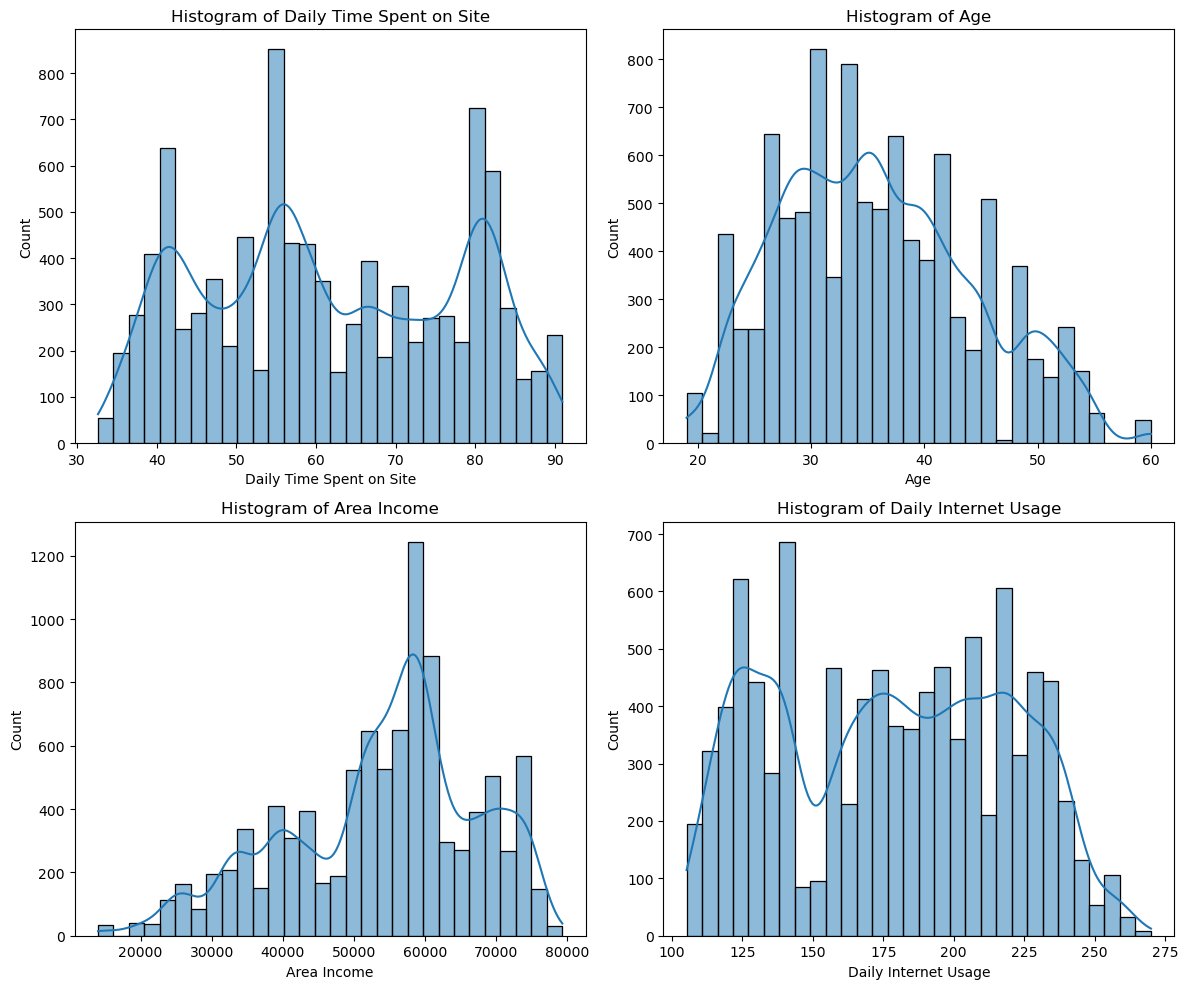

In [10]:
# Histograms for numerical features
data_num = df[['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage']]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))  
axes = axes.flatten()

# Iterate over columns and axes
for i, column in enumerate(data_num.columns):
    sns.histplot(data_num[column], kde=True, ax=axes[i], bins=30)
    axes[i].set_title(f'Histogram of {column}')

# Adjust layout
plt.tight_layout()
plt.show()


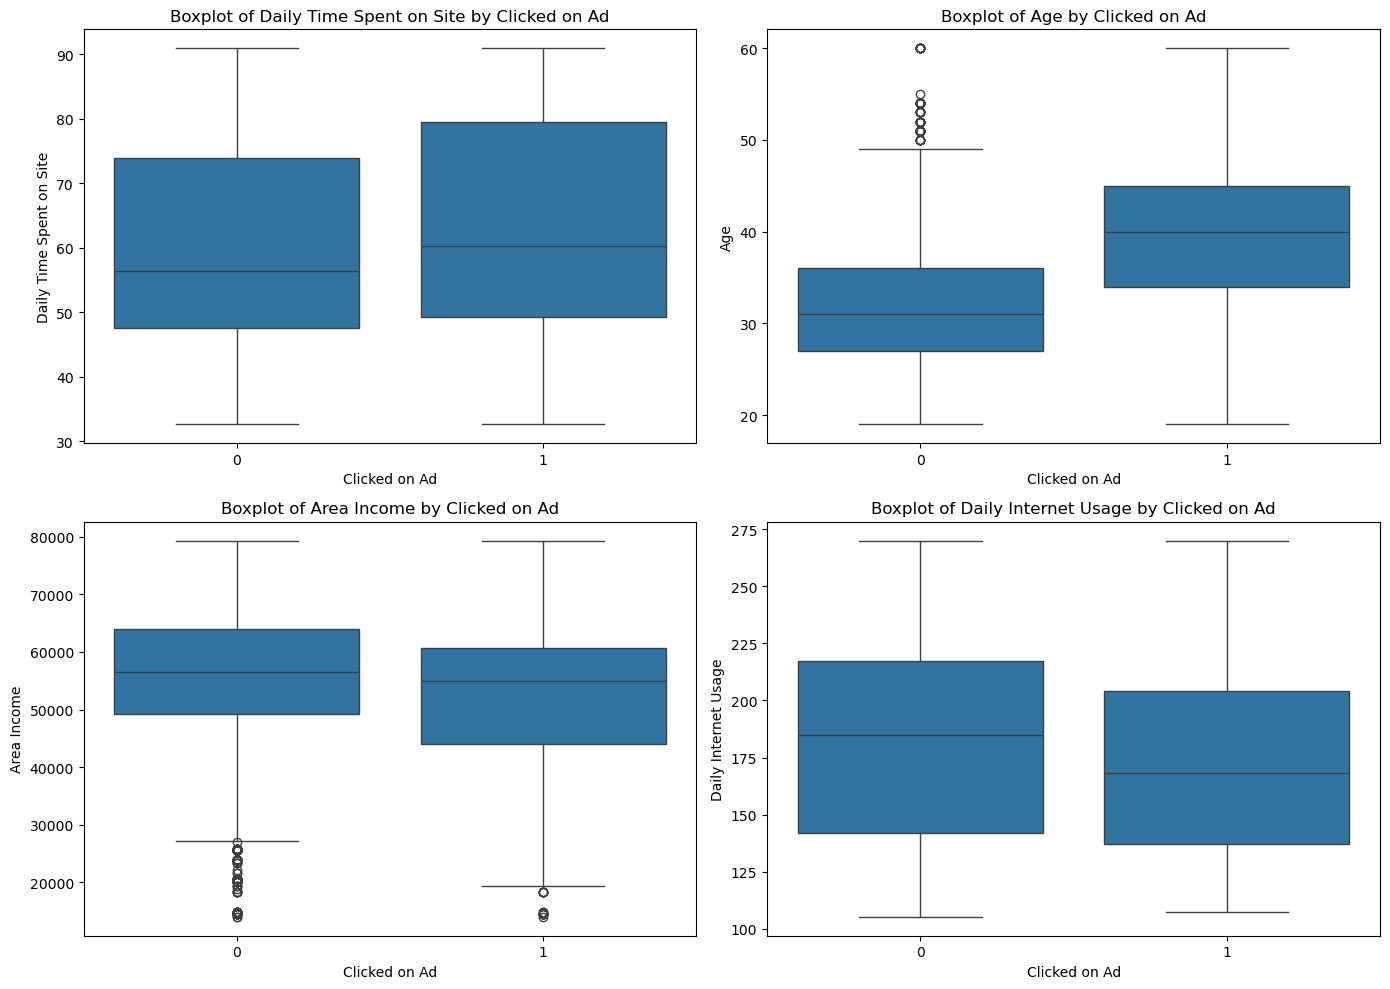

In [11]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))  # Create a 2x2 grid of subplots
target = 'Clicked on Ad'

# Loop through features and plot each boxplot in the corresponding subplot
for i, feature in enumerate(data_num):
    row, col = divmod(i, 2)  # Determine subplot position
    sns.boxplot(ax=axes[row, col], x=target, y=feature, data=df)
    axes[row, col].set_title(f'Boxplot of {feature} by {target}')
    axes[row, col].set_xlabel(target)
    axes[row, col].set_ylabel(feature)

# Adjust layout to avoid overlapping
plt.tight_layout()
plt.show()


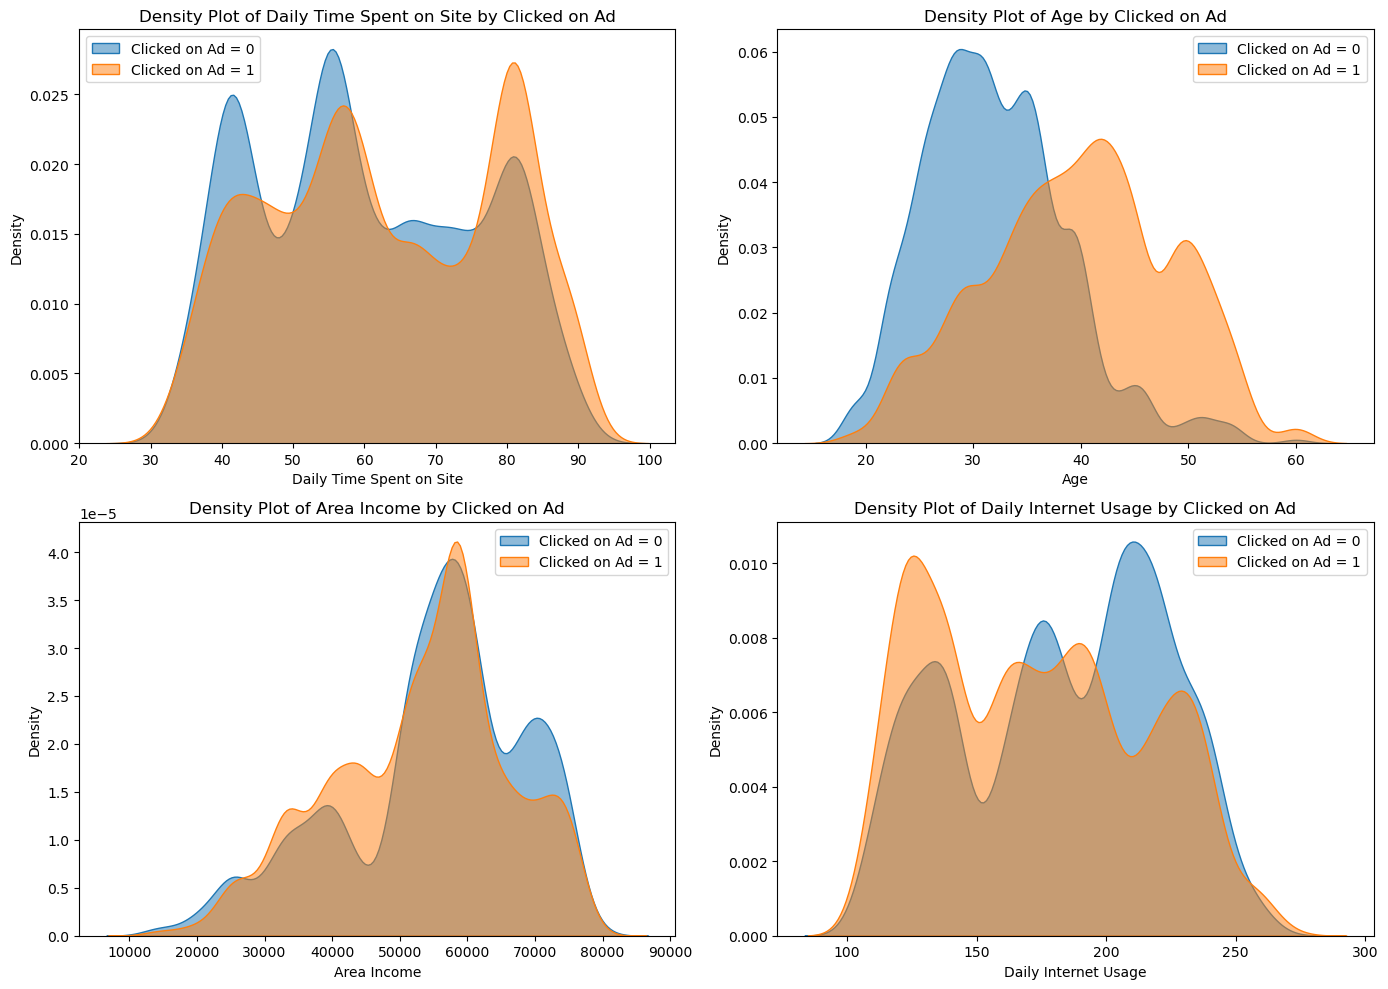

In [12]:


# Assuming data_num and target are already defined
fig, axes = plt.subplots(2, 2, figsize=(14, 10))  # Create a 2x2 grid of subplots

# Loop through features and plot density plots in the corresponding subplot
for i, feature in enumerate(data_num):
    row, col = divmod(i, 2)  # Determine subplot position
    ax = axes[row, col]
    
    # Plot density for each target group
    for label in df[target].unique():
        sns.kdeplot(
            data=df[df[target] == label][feature], 
            ax=ax, 
            label=f'{target} = {label}',
            fill=True, 
            alpha=0.5
        )
    
    ax.set_title(f'Density Plot of {feature} by {target}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Density')
    ax.legend()

# Adjust layout to avoid overlapping
plt.tight_layout()
plt.show()



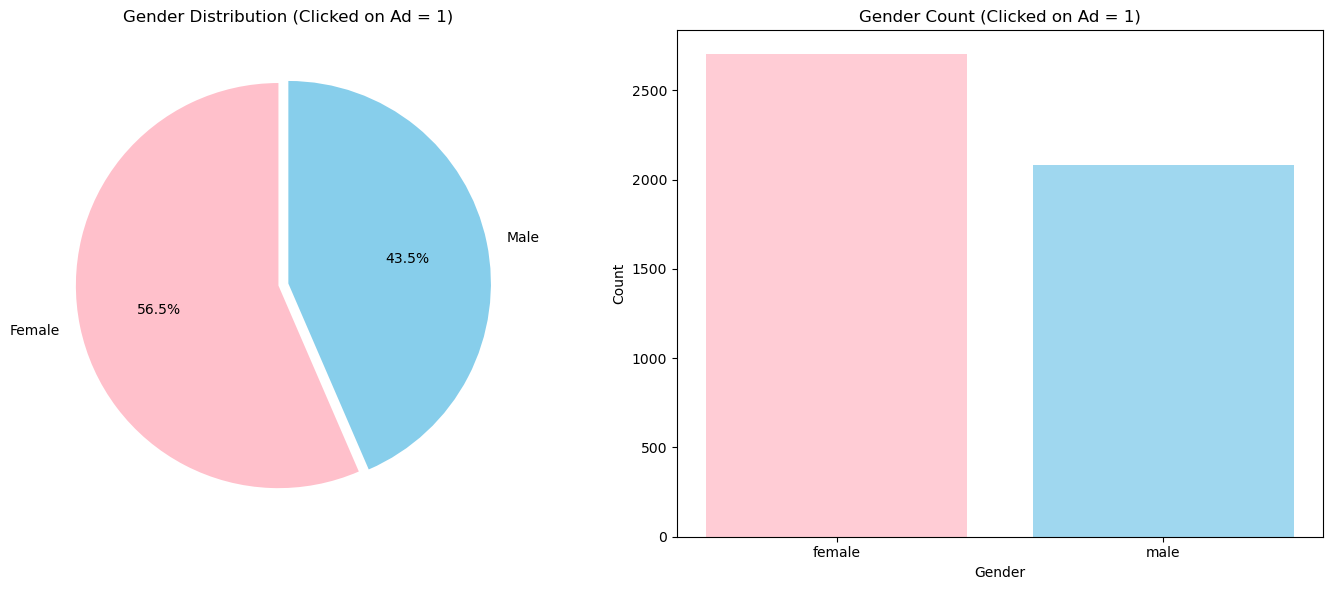

In [13]:



# Filter the data for Clicked on Ad = 1
clicked_data = df[df['Clicked on Ad'] == 1]

# Count the Gender distribution for Clicked on Ad = 1
gender_counts = clicked_data['Gender'].value_counts()

# Create subplots: 1 row, 2 columns
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie chart
axes[0].pie(
    gender_counts, 
    labels=gender_counts.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=['pink', 'skyblue'], 
    explode=(0.05, 0)  # Slightly separate slices for better visibility
)
axes[0].set_title('Gender Distribution (Clicked on Ad = 1)')

# Bar plot
axes[1].bar(
    gender_counts.index, 
    gender_counts.values, 
    color=['pink', 'skyblue'], 
    alpha=0.8
)
axes[1].set_title('Gender Count (Clicked on Ad = 1)')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Count')
axes[1].set_xticks(range(len(gender_counts)))
axes[1].set_xticklabels(['female', 'male'])

# Adjust layout
plt.tight_layout()
plt.show()


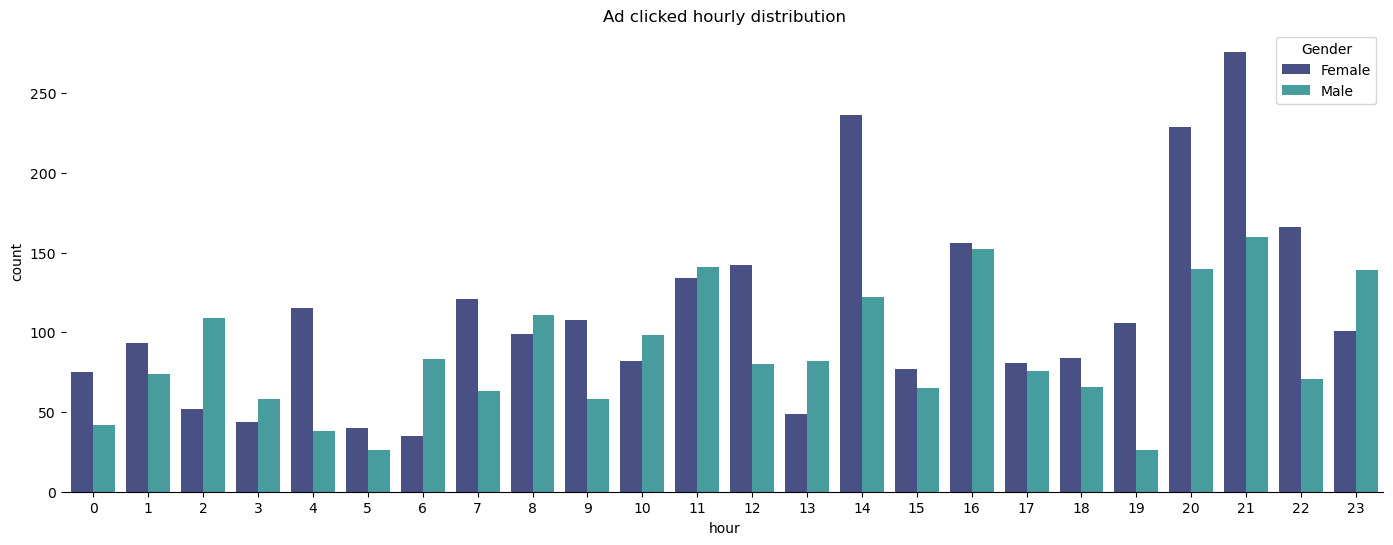

In [14]:
plt.figure(figsize=(17,6))
sns.countplot(x='hour',data=df[df['Clicked on Ad']==1],hue='Gender',palette='mako')
plt.title('Ad clicked hourly distribution')
sns.despine(left=True)
#As we can see with uneven daytime frequency, females are the main contributor exceeding males several hours.¶


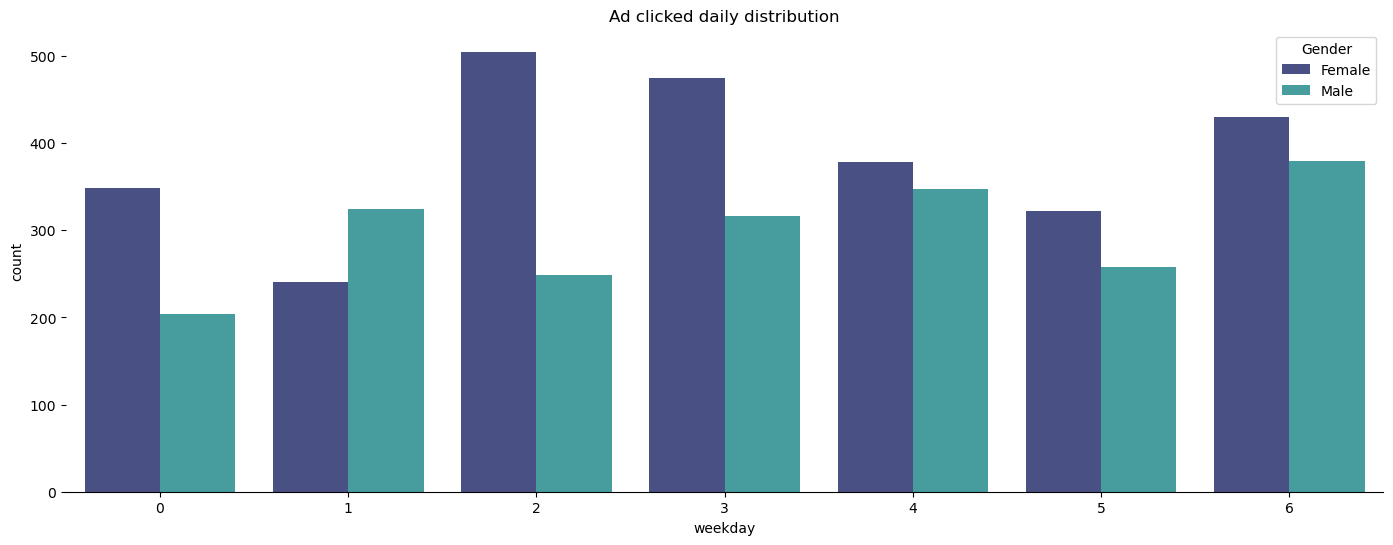

In [15]:
plt.figure(figsize=(17,6))
sns.countplot(x='weekday',data=df[df['Clicked on Ad']==1],hue='Gender',palette='mako')
plt.title('Ad clicked daily distribution')
sns.despine(left=True)

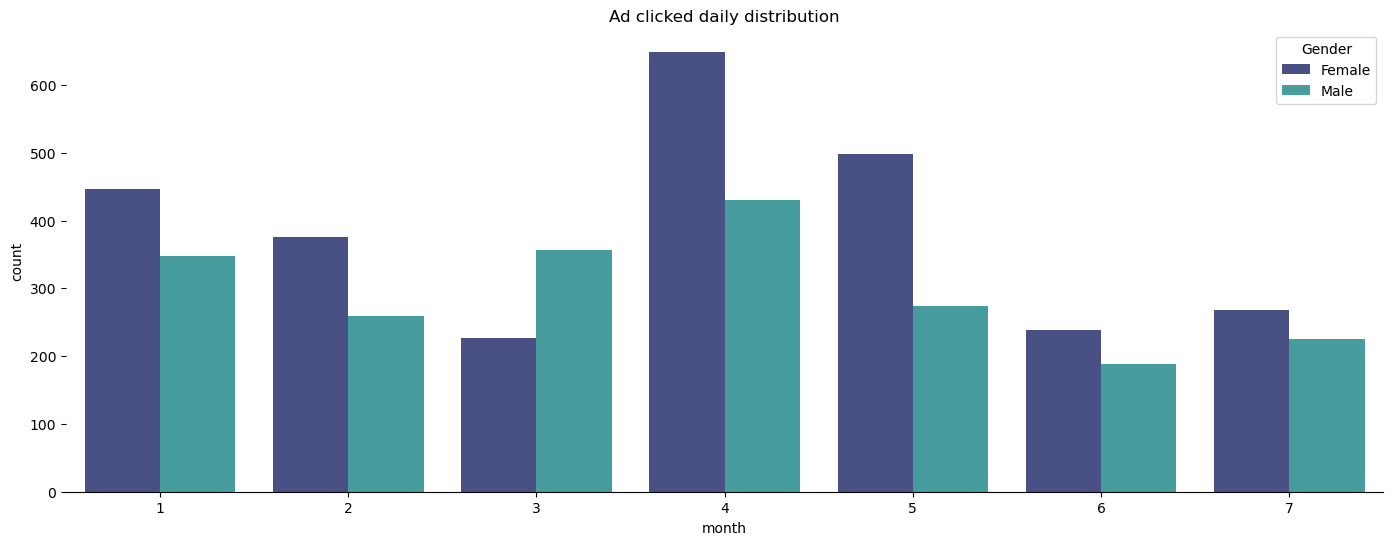

In [16]:
plt.figure(figsize=(17,6))
sns.countplot(x='month',data=df[df['Clicked on Ad']==1],hue='Gender',palette='mako')
plt.title('Ad clicked daily distribution')
sns.despine(left=True)

C:\Users\user\AppData\Local\Temp\ipykernel_13208\4063756587.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_num.loc[:, 'Clicked on Ad'] = df['Clicked on Ad']
C:\Users\user\AppData\Local\Temp\ipykernel_13208\4063756587.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_num.loc[:, 'month'] = df['month']
C:\Users\user\AppData\Local\Temp\ipykernel_13208\4063756587.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_index

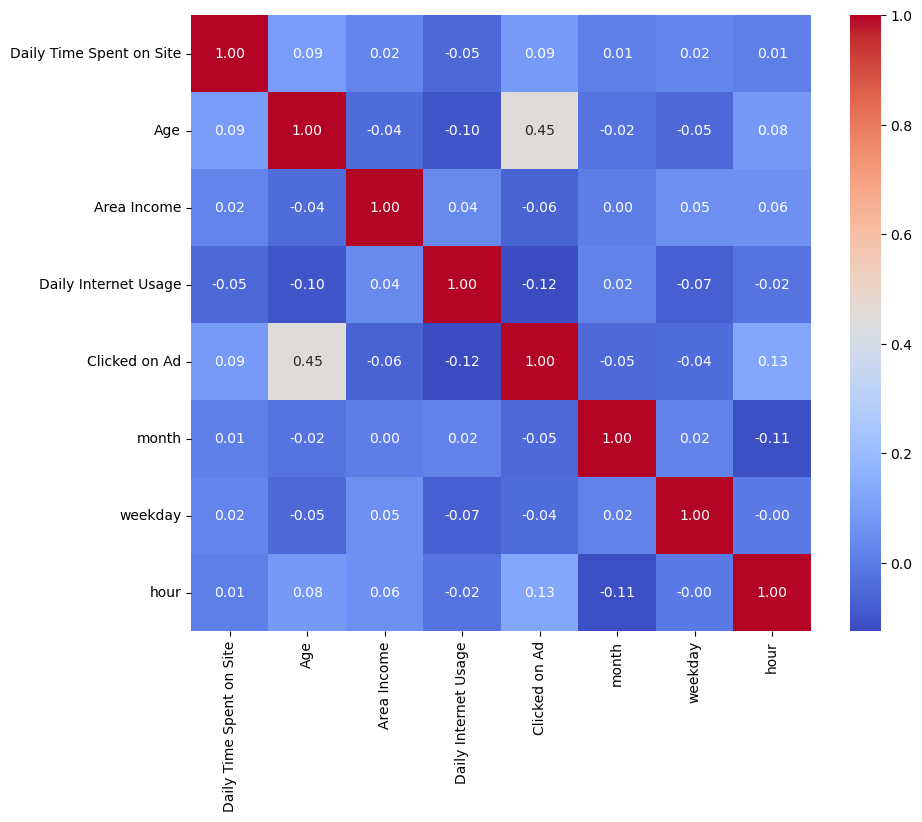

In [17]:
data_num.loc[:, 'Clicked on Ad'] = df['Clicked on Ad']
data_num.loc[:, 'month'] = df['month']
data_num.loc[:, 'weekday'] = df['weekday']
data_num.loc[:, 'hour'] = df['hour']

correlation_matrix = data_num.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot= True, fmt=".2f",cmap = 'coolwarm')
plt.show()

# Data preprocessing

In [18]:
# we need to modify some data types to be able to process them efficiently


In [19]:

# Define the categorical features
categorical_features = ['City', 'Gender', 'Ad Topic Line', 'Country']

# Select the feature columns (X) and target column (y)
X = df[['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Gender', 'Country', 'City', 'Ad Topic Line']]
y = df['Clicked on Ad']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the TargetEncoder
encoder = TargetEncoder(cols=categorical_features)

# Fit the encoder on the training data and transform both training and testing data
X_train_encoded = encoder.fit_transform(X_train, y_train)  # Fit and transform on training data
X_test_encoded = encoder.transform(X_test)  # Transform test data using training data encoding

# Step 2: Standardization
scaler = StandardScaler()

# Standardize the training and testing data
X_train_standardized = scaler.fit_transform(X_train_encoded)
X_test_standardized = scaler.transform(X_test_encoded)

# Convert back to DataFrame for easier interpretation (optional)
X_train_standardized = pd.DataFrame(X_train_standardized, columns=X_train_encoded.columns)
X_test_standardized = pd.DataFrame(X_test_standardized, columns=X_test_encoded.columns)

X_train_standardized.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Gender,Country,City,Ad Topic Line
0,-0.632510,-1.037021,-1.286382,-1.140063,-1.075395,-0.476791,-0.476774,-0.294640
1,1.098457,0.490560,1.441071,-1.614330,-1.075395,1.308416,0.121995,0.414054
2,-0.016403,-1.272034,-0.246248,0.569503,-1.075395,-1.256736,-0.522831,-0.877950
3,1.150756,0.608067,0.289098,1.198182,0.929891,-1.413442,-1.636318,0.079974
4,-0.550873,0.725573,0.290733,0.263619,-1.075395,1.142204,1.002558,1.512628


# Decision Tree

In [20]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()

dt.fit(X_train_standardized,y_train)

DecisionTreeClassifier()

In [21]:
dt_ypred_train = dt.predict(X_train_standardized)
dt_ypred_test = dt.predict(X_test_standardized)

In [22]:
from sklearn.metrics import accuracy_score
dt_sk_train_acc = accuracy_score(y_train,dt_ypred_train)
dt_sk_test_acc = accuracy_score(y_test,dt_ypred_test)
dt_sk_train_acc , dt_sk_test_acc

(0.9992335206949412, 0.8298415942769545)

# Decision Tree from scratch

In [23]:
import Decision_Tree_model

classifier = DecisionTreeClassifier(min_samples_split=2, max_depth=100)
classifier.fit(X_train_standardized,y_train) 


DecisionTreeClassifier(max_depth=100)

In [24]:
y_train_pred = classifier.predict(X_train_standardized) 
y_test_pred = classifier.predict(X_test_standardized) 
dt_train_acc = accuracy_score(y_train,y_train_pred )
dt_test_acc = accuracy_score(y_test,y_test_pred)
dt_train_acc , dt_test_acc

(0.9992335206949412, 0.8226877874297394)

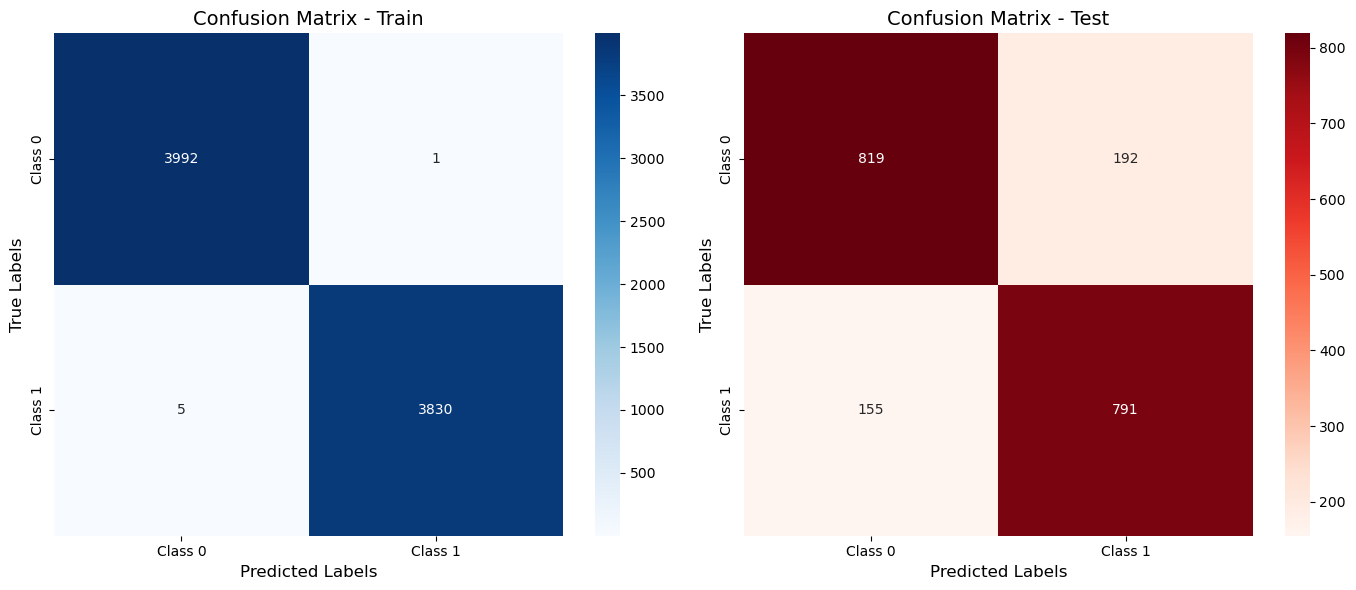

In [25]:

# Generate the confusion matrix
conf_matrix_test = confusion_matrix(y_test,y_test_pred)
conf_matrix_train = confusion_matrix(y_train,y_train_pred)

# Display the confusion matrix as a graph
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion matrix for the train set
sns.heatmap(conf_matrix_train, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'], ax=axes[0])
axes[0].set_title('Confusion Matrix - Train', fontsize=14)
axes[0].set_xlabel('Predicted Labels', fontsize=12)
axes[0].set_ylabel('True Labels', fontsize=12)

# Confusion matrix for the test set
sns.heatmap(conf_matrix_test, annot=True, fmt='d', cmap='Reds', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'], ax=axes[1])
axes[1].set_title('Confusion Matrix - Test', fontsize=14)
axes[1].set_xlabel('Predicted Labels', fontsize=12)
axes[1].set_ylabel('True Labels', fontsize=12)

# Adjusting spacing between subgraphs
plt.tight_layout()
plt.show()

In [26]:
# Classification reports
print("Classification Report - Train:")
print(classification_report(y_train,y_train_pred, target_names=['Class 0', 'Class 1']))

print("\nClassification Report - Test:")
print(classification_report(y_test,y_test_pred, target_names=['Class 0', 'Class 1']))

Classification Report - Train:
              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00      3993
     Class 1       1.00      1.00      1.00      3835

    accuracy                           1.00      7828
   macro avg       1.00      1.00      1.00      7828
weighted avg       1.00      1.00      1.00      7828


Classification Report - Test:
              precision    recall  f1-score   support

     Class 0       0.84      0.81      0.83      1011
     Class 1       0.80      0.84      0.82       946

    accuracy                           0.82      1957
   macro avg       0.82      0.82      0.82      1957
weighted avg       0.82      0.82      0.82      1957



# Naive Bayes from scratch

In [27]:
from Naive_Bayes_model import NaiveBayes

In [28]:
X_train_np = X_train_standardized.values
X_test_np = X_test_standardized.values
y_train_np = y_train.values
y_test_np = y_test.values

In [29]:
classifier = NaiveBayes()
classifier.fit(X_train_np, y_train_np)

# Make predictions on the test set
y_train_pred = classifier.predict(X_train_np) 
y_test_pred = classifier.predict(X_test_np)  

In [30]:
nb_train_acc = accuracy_score(y_train_np, y_train_pred)
nb_test_acc = accuracy_score(y_test_np, y_test_pred)
nb_train_acc , nb_test_acc

(0.8777465508431272, 0.85947879407256)

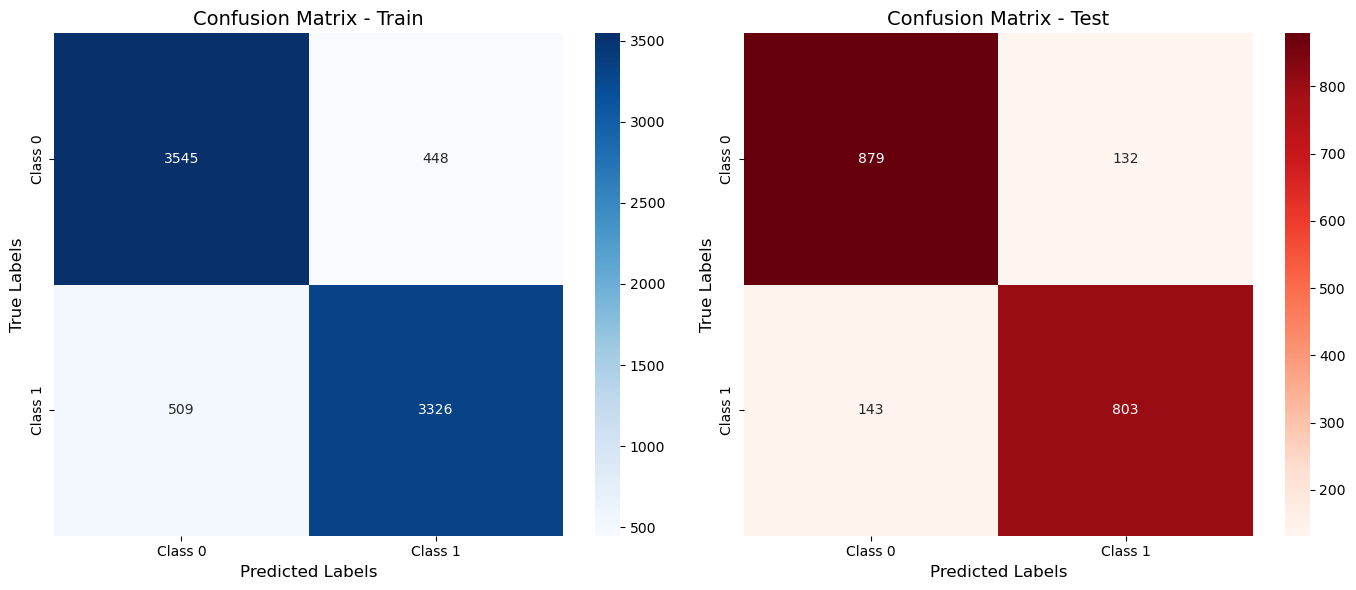

In [31]:

# Generate the confusion matrix
conf_matrix_test = confusion_matrix(y_test_np, y_test_pred)
conf_matrix_train = confusion_matrix(y_train_np, y_train_pred)

# Display the confusion matrix as a graph
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion matrix for the train set
sns.heatmap(conf_matrix_train, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'], ax=axes[0])
axes[0].set_title('Confusion Matrix - Train', fontsize=14)
axes[0].set_xlabel('Predicted Labels', fontsize=12)
axes[0].set_ylabel('True Labels', fontsize=12)

# Confusion matrix for the test set
sns.heatmap(conf_matrix_test, annot=True, fmt='d', cmap='Reds', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'], ax=axes[1])
axes[1].set_title('Confusion Matrix - Test', fontsize=14)
axes[1].set_xlabel('Predicted Labels', fontsize=12)
axes[1].set_ylabel('True Labels', fontsize=12)

# Adjusting spacing between subgraphs
plt.tight_layout()
plt.show()

In [32]:
# Classification reports
class_report = classification_report(y_test_np, y_test_pred, target_names=['Class 0', 'Class 1'])
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.86      0.87      0.86      1011
     Class 1       0.86      0.85      0.85       946

    accuracy                           0.86      1957
   macro avg       0.86      0.86      0.86      1957
weighted avg       0.86      0.86      0.86      1957



# Naive Bayes

In [33]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()
nb_model.fit(X_train_np, y_train_np)

# Step 4: Make predictions on the test data
y_test_pred = nb_model.predict(X_test_np)
y_train_pred = nb_model.predict(X_train_np) 
# Step 5: Evaluate the model
nb_sk_train_acc = accuracy_score(y_train_np, y_train_pred)
nb_sk_test_acc = accuracy_score(y_test_np, y_test_pred)
nb_sk_train_acc , nb_sk_test_acc

(0.8777465508431272, 0.85947879407256)

# Logistic regression

In [34]:
from sklearn.linear_model import LogisticRegression
logmodel = LogisticRegression(solver='lbfgs')
logmodel.fit(X_train_standardized, y_train)

LogisticRegression()

In [35]:
log_ypred_train = logmodel.predict(X_train_standardized)
log_ypred_test = logmodel.predict(X_test_encoded)

In [36]:
lg_sk_train_acc = accuracy_score(y_train,log_ypred_train)
lg_sk_test_acc = accuracy_score(y_test,log_ypred_test)
lg_sk_train_acc, lg_sk_test_acc

(0.8811957077158916, 0.5166070516096065)

# Logistic regression from scratch

In [37]:
from Logistic_Regression_model import LogisticRegression

In [38]:
lg = LogisticRegression(learning_rate=0.01, n_iterations=10000)
lg.fit(X_train_standardized,y_train)

In [39]:
lg_ypred_train = lg.predict(X_train_standardized)
lg_ypred_test = lg.predict(X_test_standardized)

In [40]:
lg_train_acc = accuracy_score(y_train,lg_ypred_train)
lg_test_acc = accuracy_score(y_test,lg_ypred_test)
lg_train_acc, lg_test_acc

(0.8813234542667348, 0.8620337250894226)

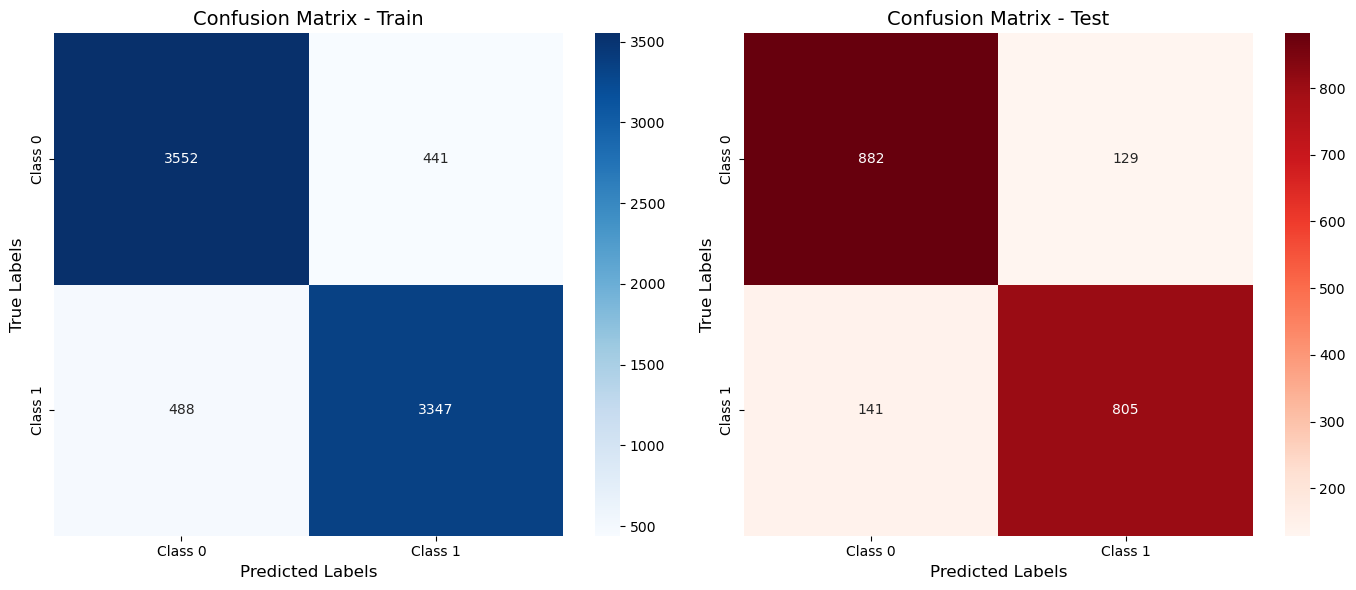

In [41]:

# Generate the confusion matrix
conf_matrix_test = confusion_matrix(y_test,lg_ypred_test)
conf_matrix_train = confusion_matrix(y_train,lg_ypred_train)

# Display the confusion matrix as a graph
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion matrix for the train set
sns.heatmap(conf_matrix_train, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'], ax=axes[0])
axes[0].set_title('Confusion Matrix - Train', fontsize=14)
axes[0].set_xlabel('Predicted Labels', fontsize=12)
axes[0].set_ylabel('True Labels', fontsize=12)

# Confusion matrix for the test set
sns.heatmap(conf_matrix_test, annot=True, fmt='d', cmap='Reds', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'], ax=axes[1])
axes[1].set_title('Confusion Matrix - Test', fontsize=14)
axes[1].set_xlabel('Predicted Labels', fontsize=12)
axes[1].set_ylabel('True Labels', fontsize=12)

# Adjusting spacing between subgraphs
plt.tight_layout()
plt.show()

In [42]:
# Classification reports
print("Classification Report - Train:")
print(classification_report(y_train,lg_ypred_train, target_names=['Class 0', 'Class 1']))

print("\nClassification Report - Test:")
print(classification_report(y_test,lg_ypred_test, target_names=['Class 0', 'Class 1']))

Classification Report - Train:
              precision    recall  f1-score   support

     Class 0       0.88      0.89      0.88      3993
     Class 1       0.88      0.87      0.88      3835

    accuracy                           0.88      7828
   macro avg       0.88      0.88      0.88      7828
weighted avg       0.88      0.88      0.88      7828


Classification Report - Test:
              precision    recall  f1-score   support

     Class 0       0.86      0.87      0.87      1011
     Class 1       0.86      0.85      0.86       946

    accuracy                           0.86      1957
   macro avg       0.86      0.86      0.86      1957
weighted avg       0.86      0.86      0.86      1957



# SVM from scratch

In [43]:
 from SVM_model import SVM

In [44]:
model = SVM()
model.fit(X_train_np, y_train_np)

In [45]:
# Make predictions on the test data
y_train_pred = model.predict(X_train_np) 
y_test_pred = model.predict(X_test_np)  

In [46]:
# Evaluate the model
svm_train_acc = accuracy_score(y_train_np, y_train_pred)
svm_test_acc = accuracy_score(y_test_np, y_test_pred)
svm_train_acc , svm_test_acc

(0.8794072560040879, 0.8620337250894226)

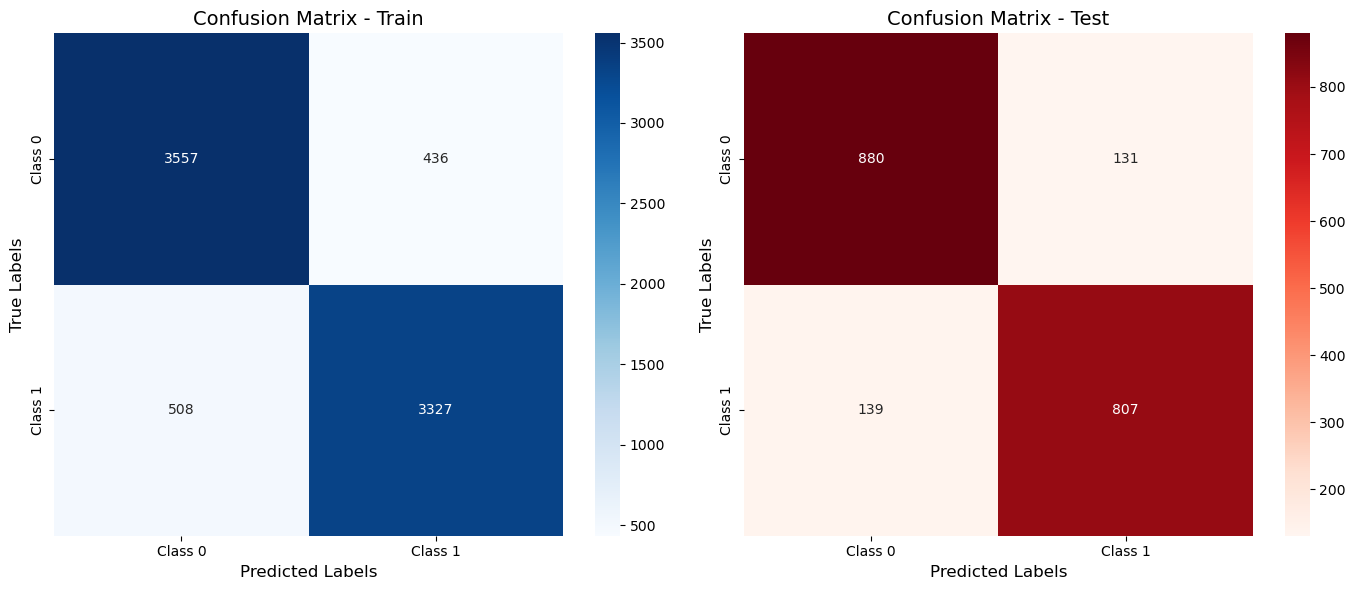

In [47]:

# Generate the confusion matrix
conf_matrix_test = confusion_matrix(y_test_np, y_test_pred)
conf_matrix_train = confusion_matrix(y_train_np, y_train_pred)

# Display the confusion matrix as a graph
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion matrix for the train set
sns.heatmap(conf_matrix_train, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'], ax=axes[0])
axes[0].set_title('Confusion Matrix - Train', fontsize=14)
axes[0].set_xlabel('Predicted Labels', fontsize=12)
axes[0].set_ylabel('True Labels', fontsize=12)

# Confusion matrix for the test set
sns.heatmap(conf_matrix_test, annot=True, fmt='d', cmap='Reds', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'], ax=axes[1])
axes[1].set_title('Confusion Matrix - Test', fontsize=14)
axes[1].set_xlabel('Predicted Labels', fontsize=12)
axes[1].set_ylabel('True Labels', fontsize=12)

# Adjusting spacing between subgraphs
plt.tight_layout()
plt.show()

In [48]:
# Classification reports
print("Classification Report - Train:")
print(classification_report(y_train_np, y_train_pred, target_names=['Class 0', 'Class 1']))

print("\nClassification Report - Test:")
print(classification_report(y_test_np, y_test_pred, target_names=['Class 0', 'Class 1']))

Classification Report - Train:
              precision    recall  f1-score   support

     Class 0       0.88      0.89      0.88      3993
     Class 1       0.88      0.87      0.88      3835

    accuracy                           0.88      7828
   macro avg       0.88      0.88      0.88      7828
weighted avg       0.88      0.88      0.88      7828


Classification Report - Test:
              precision    recall  f1-score   support

     Class 0       0.86      0.87      0.87      1011
     Class 1       0.86      0.85      0.86       946

    accuracy                           0.86      1957
   macro avg       0.86      0.86      0.86      1957
weighted avg       0.86      0.86      0.86      1957



# SVM

In [49]:
from sklearn.svm import SVC
skmodel = SVC()

In [50]:
skmodel.fit(X_train_np, y_train_np)

SVC()

In [51]:
# Make predictions on the test data
y_train_pred = skmodel.predict(X_train_np) 
y_test_pred = skmodel.predict(X_test_np)

In [52]:
# Evaluate the model
svm_sk_train_acc = accuracy_score(y_train_np, y_train_pred)
svm_sk_test_acc = accuracy_score(y_test_np, y_test_pred)
svm_sk_train_acc , svm_sk_test_acc

(0.8911599386816556, 0.8691875319366377)

# Compare Model Accuracy

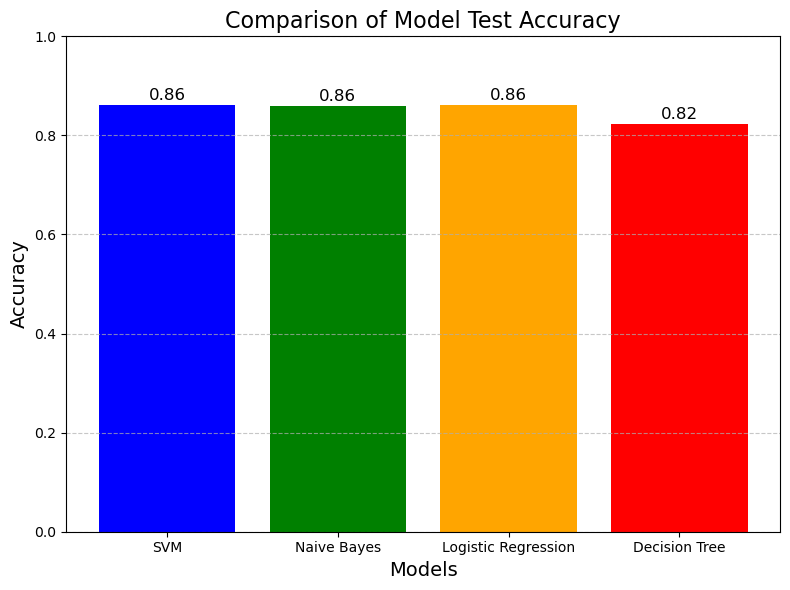

In [53]:

models = ['SVM', 'Naive Bayes', 'Logistic Regression', 'Decision Tree']
accuracies = [ svm_test_acc , nb_test_acc , lg_test_acc , dt_test_acc]  #accuracy for each model

# Creating the graph
plt.figure(figsize=(8, 6))
plt.bar(models, accuracies, color=['blue', 'green', 'orange', 'red'])

# Add labels and title
plt.xlabel('Models', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.title('Comparison of Model Test Accuracy', fontsize=16)
plt.ylim(0, 1)  # Les accuracy sont entre 0 et 1
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add accuracy values above the bars
for i, acc in enumerate(accuracies):
    plt.text(i, acc + 0.01, f"{acc:.2f}", ha='center', fontsize=12)

# Display the graph
plt.tight_layout()
plt.show()

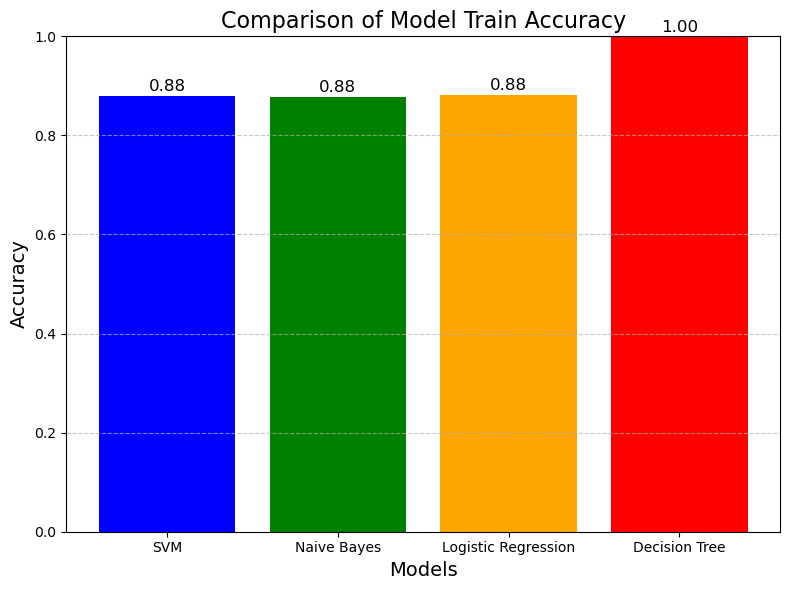

In [54]:
models = ['SVM', 'Naive Bayes', 'Logistic Regression', 'Decision Tree']
accuracies = [ svm_train_acc , nb_train_acc , lg_train_acc , dt_train_acc]  #accuracy for each model

# Creating the graph
plt.figure(figsize=(8, 6))
plt.bar(models, accuracies, color=['blue', 'green', 'orange', 'red'])

# Add labels and title
plt.xlabel('Models', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.title('Comparison of Model Train Accuracy', fontsize=16)
plt.ylim(0, 1)  # Les accuracy sont entre 0 et 1
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add accuracy values above the bars
for i, acc in enumerate(accuracies):
    plt.text(i, acc + 0.01, f"{acc:.2f}", ha='center', fontsize=12)

# Display the graph
plt.tight_layout()
plt.show()